# Trabalho Final de Machine Learning — Predição e Classificação da Qualidade de Vinhos

**Equipe:** Grupo 1

**Dataset:** `group_1_winequality.csv` — dados físico-químicos de vinhos tintos e brancos com nota de qualidade sensorial (0 a 10).

**Objetivo:** construir um pipeline completo de Machine Learning em duas partes:
1. **Regressão** — prever a nota `quality` como valor contínuo;
2. **Classificação** — agrupar as notas em faixas e prever a faixa.

Roteiro do notebook:
0. Configuração e bibliotecas
1. Carregamento e limpeza dos dados
2. Análise exploratória (histogramas, scatter plots, correlação)
3. Pré-processamento (ausentes, outliers, padronização)
4. Parte 1 — Regressão
5. Parte 2 — Classificação
6. Conclusões

## 0. Configuração
Bibliotecas usadas: `pandas`/`numpy` (dados), `matplotlib`/`seaborn` (gráficos),
`scikit-learn` (modelos e métricas) e `imbalanced-learn` (SMOTENC para balanceamento).

Se faltar alguma: `pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn`

In [1]:
import os
from pathlib import Path

# Paraleliza as dobras em threads, limitando as threads internas de cada ajuste.
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import BaseEstimator, OneToOneFeatureMixin, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import (HistGradientBoostingClassifier, HistGradientBoostingRegressor,
                              RandomForestClassifier, RandomForestRegressor)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (ConfusionMatrixDisplay, balanced_accuracy_score, classification_report, confusion_matrix,
                             f1_score, mean_absolute_error, r2_score, root_mean_squared_error)
from sklearn.model_selection import (GridSearchCV, KFold, StratifiedKFold, cross_validate,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.utils.validation import validate_data
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from joblib import parallel_config

from IPython.display import display
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

SEED = 42                       # semente fixa -> resultados reprodutíveis
RAIZ_PROJETO = Path.cwd()
CAMINHO_CSV = RAIZ_PROJETO / "dados/group_1_winequality.csv"
N_JOBS = min(6, os.cpu_count() or 1)

## 1. Carregamento e limpeza dos dados

Antes de qualquer análise, inspecionamos o arquivo bruto. Ao ler o CSV percebemos que
**ele não está limpo**: algumas colunas que deveriam ser numéricas vieram como texto e
vários valores estão em escala errada.

In [2]:
from limpeza import COLUNAS_NUMERICAS, ler_csv, limpar_dados

bruto = ler_csv(CAMINHO_CSV)
print(bruto.shape)
print(bruto.dtypes)
bruto.describe().T

(6497, 13)
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                  object
type                     object
quality                 float64
dtype: object


,count,mean,std,min,25%,50%,75%,max
fixed acidity,6346.0,7.224070,1.471913,3.80,6.400,7.000,7.700,63.000
volatile acidity,6496.0,28.514717,131.028738,0.08,0.230,0.300,0.420,975.000
citric acid,6496.0,0.321562,0.277260,0.00,0.250,0.310,0.390,19.350
residual sugar,6496.0,5.454618,4.828859,0.60,1.800,3.000,8.100,72.000
chlorides,6496.0,49.887672,40.569811,0.02,34.000,45.000,59.000,1369.000
free sulfur dioxide,6496.0,30.817426,29.442045,1.00,17.000,29.000,41.000,1924.000
total sulfur dioxide,6496.0,116.108605,63.399395,6.00,77.000,118.000,156.000,2430.000
density,6496.0,112.117052,234.952804,0.99,9.953,98.963,99.526,4365.944
pH,6496.0,3.231449,1.057750,2.72,3.110,3.210,3.320,87.480
sulphates,6496.0,0.534009,0.267513,0.22,0.430,0.510,0.600,18.450


In [3]:
# Exemplos de problemas encontrados no arquivo bruto
print("type:", bruto["type"].value_counts(dropna=False).to_dict())
print("quality:", bruto["quality"].value_counts(dropna=False).sort_index().to_dict())
alc = pd.to_numeric(bruto["alcohol"], errors="coerce")
print("alcohol não numérico (amostra):", bruto.loc[alc.isna() & bruto["alcohol"].notna(), "alcohol"].str.slice(0, 32).head(5).tolist())
print("chlorides acima de 1 (amostra):", bruto.loc[bruto["chlorides"] > 1, "chlorides"].head(5).tolist())
print("density acima de 1.04 (amostra):", bruto.loc[bruto["density"] > 1.04, "density"].head(5).tolist())
print("linhas duplicadas:", bruto.duplicated().sum())

type: {'white': 4896, 'red': 1599, 'whitewhitewhitewhitewhitewhitewhitewhitewhitewhitewhitewhitewhitewhitewhitewhitewhitewhitewhite': 1, nan: 1}
quality: {3.0: 30, 4.0: 216, 5.0: 2138, 6.0: 2835, 7.0: 1078, 8.0: 193, 9.0: 5, 238.0: 1, nan: 1}
alcohol não numérico (amostra): ['100.333.333.333.333', '100.333.333.333.333', '110.666.666.666.667', '956.666.666.666.667', '135.666.666.666.667']
chlorides acima de 1 (amostra): [76.0, 98.0, 92.0, 75.0, 76.0]
density acima de 1.04 (amostra): [9.978, 9.968, 997.0, 998.0, 9.978]
linhas duplicadas: 1123


### Diagnóstico
O CSV tinha 6.497 linhas. Reparamos 5.765 valores de cloretos, 6.330 de densidade, 343 de acidez volátil, 41 registros de álcool em texto e um rótulo repetido de vinho branco. Excluímos duas linhas por nota inválida (uma ausente e uma igual a 238), uma por tipo ausente e 1.125 por duplicidade após os reparos. Restaram 5.369 vinhos, com 152 valores ausentes de acidez fixa e 71 de densidade, as duas maiores contagens de ausência.

### Estratégia de limpeza
- **Escala decimal**: dividimos os inteiros fora da faixa de cloretos e acidez volátil por 1.000.
  Para densidade, testamos potências de 10 dentro de uma faixa física plausível. Ex.: 76 → 0,076
  em cloretos e 9,978 → 0,9978 em densidade.
- **Álcool em texto**: reparamos a formatação de milhar e a repetição textual quando reconhecíveis.
- **Valores impossíveis sem padrão reconhecido**: marcamos como ausentes.
- **Tipo**: repetições de um mesmo rótulo são normalizadas. Excluímos linhas sem tipo válido.
- **Alvo**: removemos notas ausentes, fracionárias ou fora de 0–10.
- **Duplicatas**: removemos após normalizar, antes da divisão de treino e teste.

O notebook importa a limpeza de `limpeza.py`, que também pode ser executado pelo terminal.

In [4]:
df, auditoria = limpar_dados(bruto, verbose=False)
chaves_remocao = ["linhas_quality_invalida_removidas", "linhas_sem_type_removidas", "duplicadas_removidas"]
assert len(bruto) - sum(auditoria[chave] for chave in chaves_remocao) == len(df)
assert pd.api.types.is_integer_dtype(df["quality"]) and df["quality"].between(0, 10).all()
assert df["type"].isin(["red", "white"]).all()
assert not df.duplicated().any()

print("Auditoria de linhas:", {k: v for k, v in auditoria.items() if isinstance(v, int)})
tabela_limpeza = pd.DataFrame(auditoria["numericas"]).T
tabela_limpeza["ausentes após limpeza"] = df[tabela_limpeza.index].isna().sum()
display(tabela_limpeza)

Auditoria de linhas: {'linhas_originais': 6497, 'duplicadas_no_bruto': 1123, 'alcohol_texto_corrompido': 41, 'tipos_normalizados': 1, 'linhas_quality_invalida_removidas': 2, 'linhas_sem_type_removidas': 1, 'duplicadas_removidas': 1125, 'linhas_finais': 5369}


,ausentes no bruto,corrigidos,viraram ausentes,ausentes após limpeza
fixed acidity,151,0,1,152
volatile acidity,1,343,0,1
citric acid,1,0,1,2
residual sugar,1,0,1,2
chlorides,1,5765,1,2
free sulfur dioxide,1,0,1,2
total sulfur dioxide,1,0,1,2
density,1,6330,96,71
pH,1,0,1,2
sulphates,1,0,1,2


In [5]:
# Médias calculadas nos dois CSVs originais da UCI, DOI 10.24432/C56S3T.
# A comparação é agregada: deduplicação e imputáveis podem mudar as médias do grupo.
medias_uci = pd.DataFrame({
    "chlorides": {"red": 0.08746654, "white": 0.04577236},
    "volatile acidity": {"red": 0.52782051, "white": 0.27824112},
    "density": {"red": 0.99674668, "white": 0.99402738},
})
medias_uci.index.name = "type"
medias_grupo = df.groupby("type")[medias_uci.columns].mean()
comparacao_uci = pd.concat({"Grupo 1 (limpo)": medias_grupo, "UCI (bruto)": medias_uci}, axis=1)
display(comparacao_uci.round(5))

Grupo 1 (limpo)                           UCI (bruto)                   \
            chlorides volatile acidity  density   chlorides volatile acidity   
type                                                                           
red           0.08803          0.53016  0.99659     0.08747          0.52782   
white         0.04588          0.28040  0.99375     0.04577          0.27824   

                
       density  
type            
red    0.99675  
white  0.99403

In [6]:
FEATURES_NUM = COLUNAS_NUMERICAS
X, y = df[FEATURES_NUM + ["type"]], df["quality"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)
assert X_train.index.intersection(X_test.index).empty
assert len(X_train) + len(X_test) == len(df)
perfis_treino = set(pd.util.hash_pandas_object(X_train, index=False))
perfis_teste = set(pd.util.hash_pandas_object(X_test, index=False))
print("Perfis físico-químicos iguais nos dois conjuntos:", len(perfis_treino & perfis_teste))
treino = df.loc[X_train.index]
print("Treino:", len(X_train), "| teste:", len(X_test))

Perfis físico-químicos iguais nos dois conjuntos: 0
Treino: 4295 | teste: 1074


## 2. Análise exploratória (EDA)
Os gráficos e resumos desta seção usam somente o conjunto de treino.

### 2.1 Distribuição do alvo `quality`

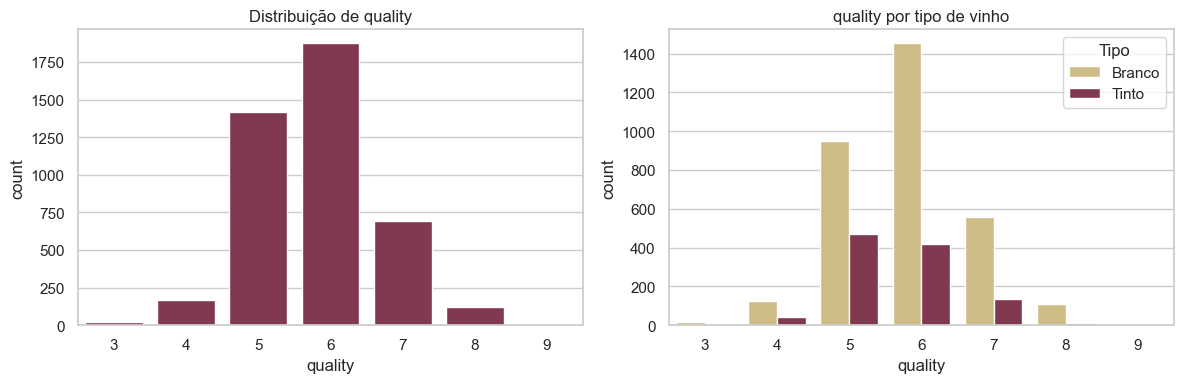

quality
3    0.006
4    0.039
5    0.330
6    0.436
7    0.161
8    0.028
9    0.001
Name: proportion, dtype: float64


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="quality", data=treino, ax=ax[0], color="#8c2d4a")
ax[0].set_title("Distribuição de quality")
sns.countplot(x="quality", hue="type", data=treino, ax=ax[1], palette={"red": "#8c2d4a", "white": "#d9c27a"})
ax[1].legend(title="Tipo", labels=["Tinto" if t.get_text() == "red" else "Branco" for t in ax[1].legend_.texts])
ax[1].set_title("quality por tipo de vinho")
plt.tight_layout()
plt.show()
print(treino["quality"].value_counts(normalize=True).sort_index().round(3))

As notas 5, 6 e 7 somam 3.980 de 4.295 observações no treino (92,7%). A nota 6 é a mais comum, com 1.873 casos (43,6%), enquanto a nota 9 tem quatro casos. A média é 5,86 para brancos e 5,61 para tintos no treino. Como os extremos são pouco representados, o modelo tem menos exemplos para aprender seus padrões.

### 2.2 Histogramas das variáveis físico-químicas

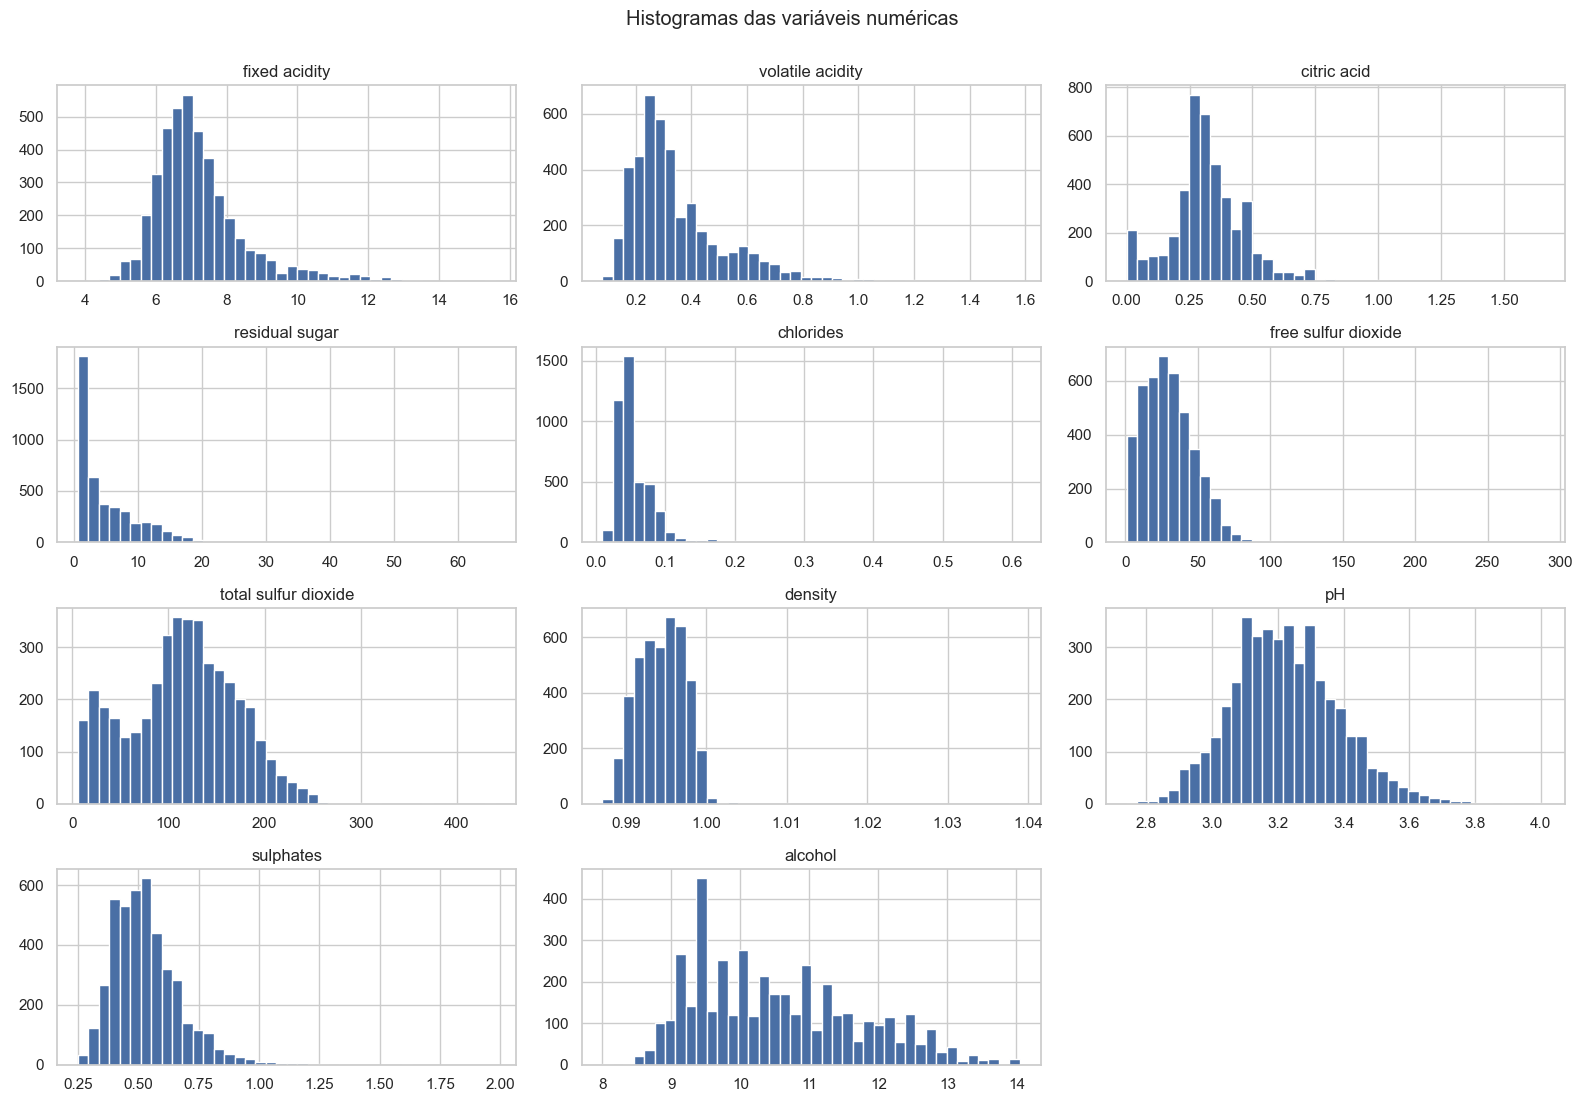

In [8]:
eixos_hist = treino[FEATURES_NUM].hist(bins=40, figsize=(16, 11), color="#4a6fa5", edgecolor="white")
fig = eixos_hist.flat[0].figure
plt.suptitle("Histogramas das variáveis numéricas", y=1.0)
plt.tight_layout()
plt.show()

Cloretos (assimetria de 5,03), açúcar residual (1,79) e SO₂ livre (1,48) apresentam caudas à direita. O SO₂ total tem assimetria de 0,07, embora as distribuições por tipo possam diferir. A mediana reduz a influência dessas caudas sobre a imputação.

### 2.3 Boxplots — detecção visual de outliers

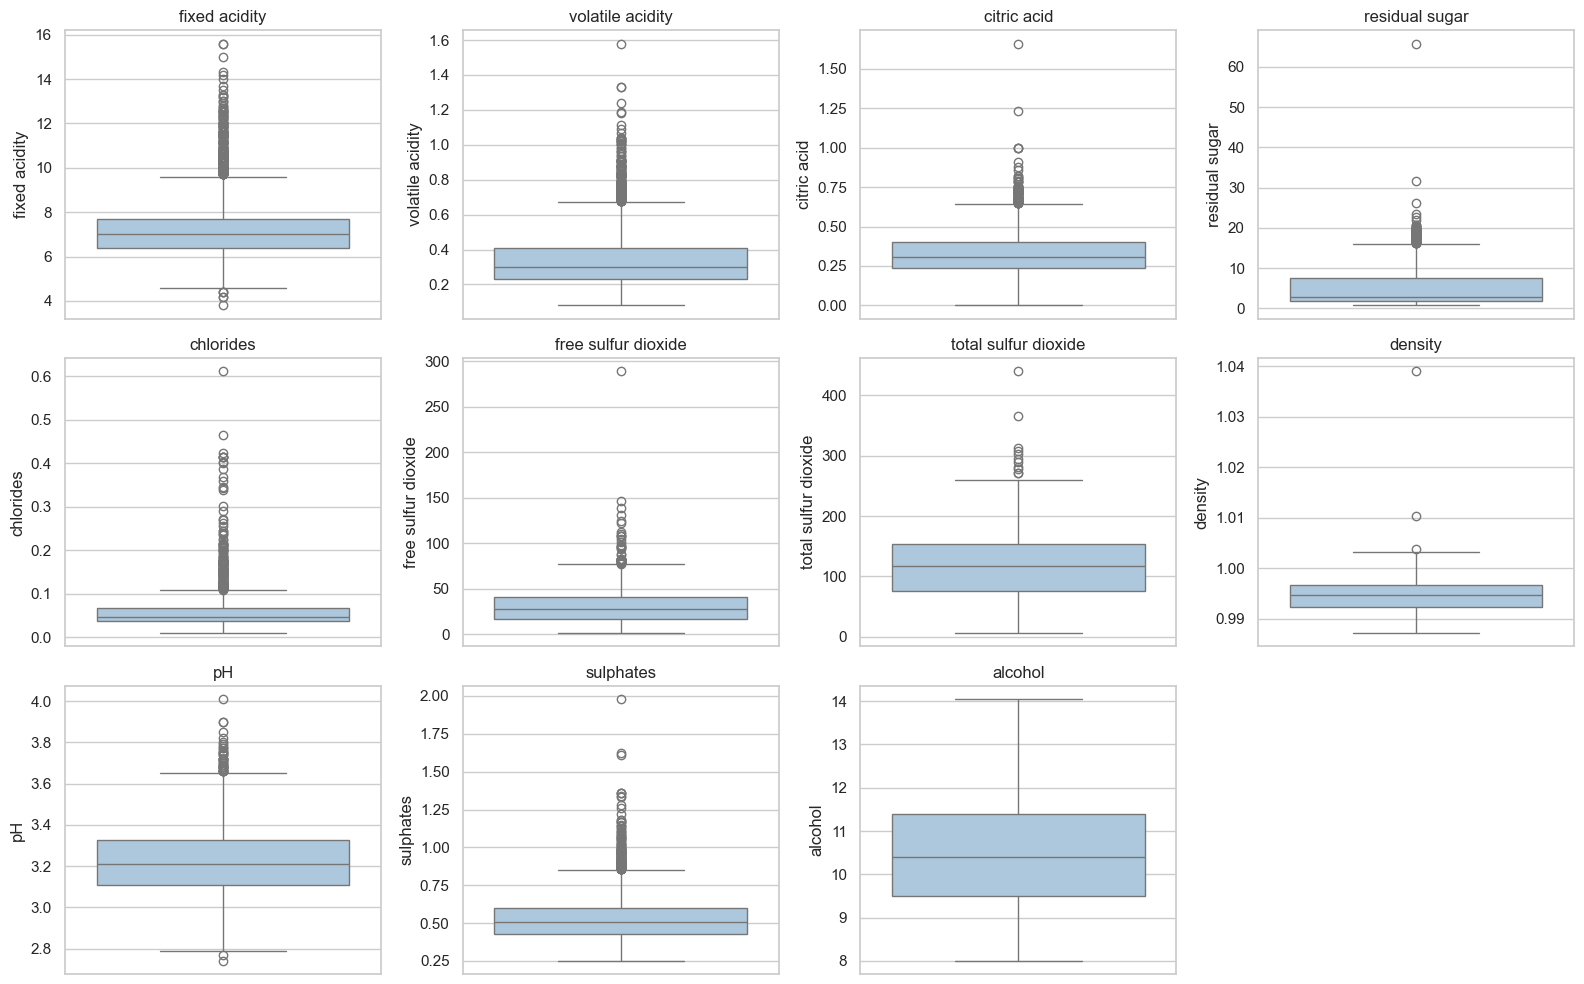

,outliers (IQR)
fixed acidity,249
volatile acidity,215
chlorides,185
sulphates,127
citric acid,114
residual sugar,110
pH,43
free sulfur dioxide,42
total sulfur dioxide,11
density,3


In [9]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, FEATURES_NUM):
    sns.boxplot(y=treino[col], ax=ax, color="#a5c8e4")
    ax.set_title(col)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

# Contagem de outliers pelo critério IQR (1,5 × intervalo interquartil)
q1, q3 = treino[FEATURES_NUM].quantile(0.25), treino[FEATURES_NUM].quantile(0.75)
iqr = q3 - q1
outliers_iqr = ((treino[FEATURES_NUM] < q1 - 1.5 * iqr) | (treino[FEATURES_NUM] > q3 + 1.5 * iqr)).sum()
outliers_iqr.sort_values(ascending=False).to_frame("outliers (IQR)")

Pelo critério de 1,5 vezes o intervalo interquartil, a acidez fixa tem 249 observações sinalizadas, a acidez volátil tem 215 e os cloretos têm 185. A regra IQR descreve extremos estatísticos. A limitação pelos percentis 1 e 99 preserva as linhas para modelagem, incluindo vinhos de notas raras.

### 2.4 Matriz de correlação

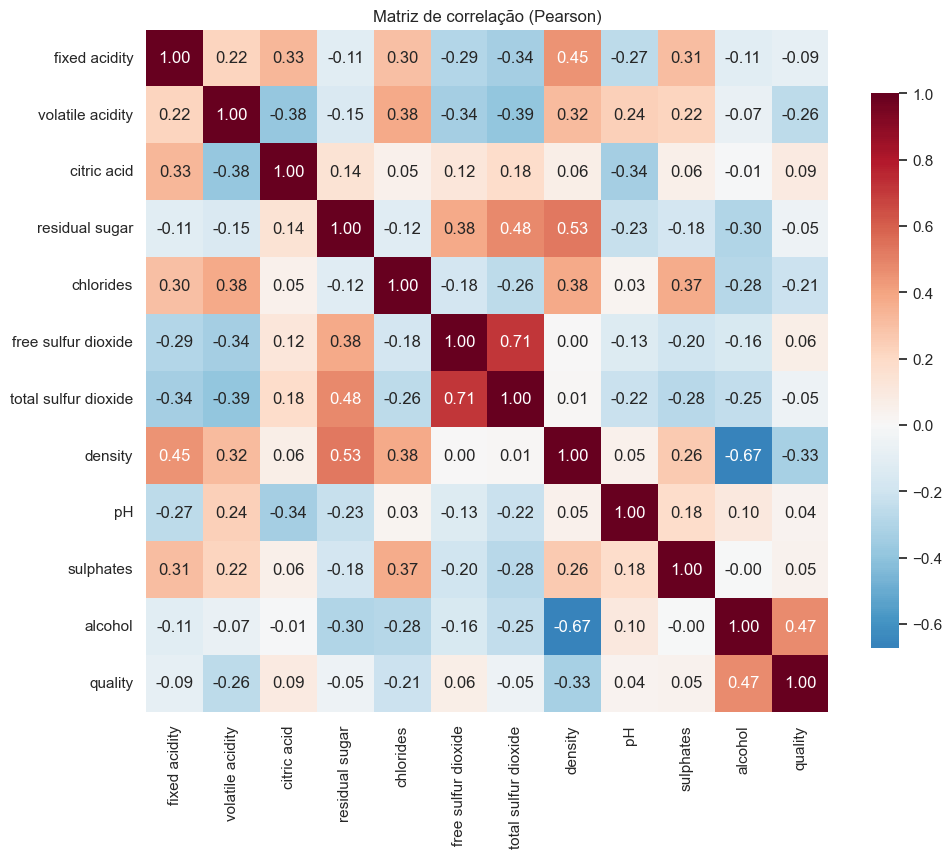

,corr. com quality
alcohol,0.472421
density,-0.331271
volatile acidity,-0.263640
chlorides,-0.212801
citric acid,0.090242
fixed acidity,-0.088510
free sulfur dioxide,0.060297
total sulfur dioxide,-0.049854
residual sugar,-0.048236
sulphates,0.046754


In [10]:
corr = treino[FEATURES_NUM + ["quality"]].corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True, cbar_kws={"shrink": .8})
plt.title("Matriz de correlação (Pearson)")
plt.show()
corr["quality"].drop("quality").sort_values(key=abs, ascending=False).to_frame("corr. com quality")

No treino, as maiores correlações absolutas com a nota são álcool (+0,47), densidade (−0,33), acidez volátil (−0,26) e cloretos (−0,21). Densidade e álcool têm correlação de −0,67, densidade e açúcar residual de +0,53, e SO₂ livre e total de +0,71. A colinearidade torna a leitura isolada dos coeficientes menos direta.

### 2.5 Scatter plots das variáveis mais relacionadas à qualidade

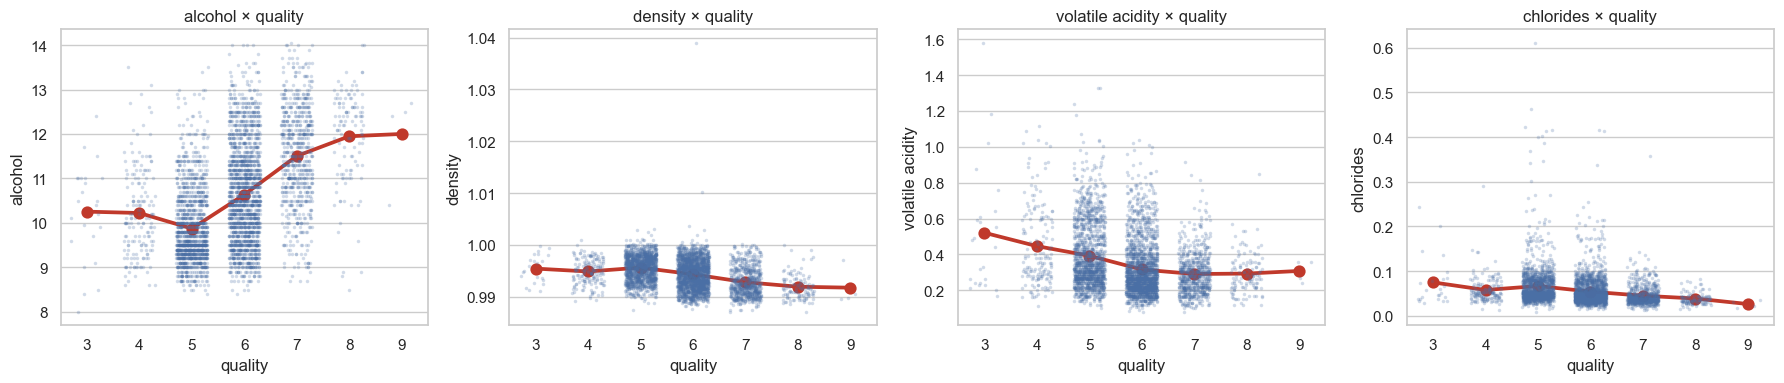

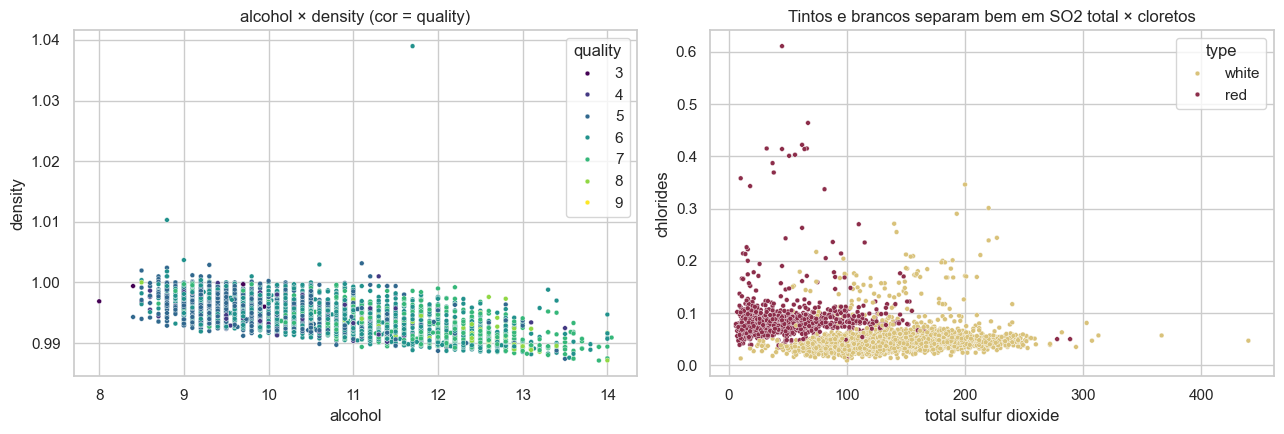

In [11]:
top4 = corr["quality"].drop("quality").abs().sort_values(ascending=False).index[:4]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, top4):
    sns.stripplot(x="quality", y=col, data=treino, ax=ax, alpha=.25, jitter=.3, size=2.5, color="#4a6fa5")
    sns.pointplot(x="quality", y=col, data=treino, ax=ax, color="#c0392b", errorbar=None)
    ax.set_title(f"{col} × quality")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(x="alcohol", y="density", hue="quality", data=treino, palette="viridis", s=12, ax=ax[0])
ax[0].set_title("alcohol × density (cor = quality)")
sns.scatterplot(x="total sulfur dioxide", y="chlorides", hue="type", data=treino, s=12, ax=ax[1],
                palette={"red": "#8c2d4a", "white": "#d9c27a"})
ax[1].set_title("Tintos e brancos separam bem em SO2 total × cloretos")
plt.tight_layout()
plt.show()

Entre as notas 5 e 8, o álcool médio passa de 9,87 para 11,95, e a densidade média cai de 0,9956 para 0,9919. As nuvens de pontos se sobrepõem, de modo que essas tendências ajudam a estimar a nota em conjunto com outras medidas. A separação por tipo aparece na dispersão de SO₂ total e cloretos. A média de cloretos no conjunto limpo é 0,0880 nos tintos e 0,0459 nos brancos.

## 3. Pré-processamento

Decisões (todas aplicadas **dentro de um `Pipeline`**, ajustadas só no treino):
1. **Ausentes** → `SimpleImputer(strategy="median")` (mediana é robusta a outliers).
2. **Outliers** → não removemos linhas (perderíamos vinhos reais e raros, inclusive das notas extremas);
   em vez disso, **limitamos (winsorização)** cada variável aos percentis 1% e 99% do treino.
3. **Padronização** → `StandardScaler` (média 0, desvio 1). Útil para modelos lineares e SVM e
   permite comparar coeficientes entre variáveis.
4. **`type`** → `OneHotEncoder` (vira a variável binária `type_white`).

In [12]:
class LimitadorQuantis(OneToOneFeatureMixin, TransformerMixin, BaseEstimator):
    """Winsorização: corta valores abaixo/acima dos quantis aprendidos no treino."""

    def __init__(self, inferior=0.01, superior=0.99):
        self.inferior = inferior
        self.superior = superior

    def fit(self, X, y=None):
        X = validate_data(self, X, dtype=float)
        self.lim_inf_ = np.nanquantile(X, self.inferior, axis=0)
        self.lim_sup_ = np.nanquantile(X, self.superior, axis=0)
        return self

    def transform(self, X):
        X = validate_data(self, X, reset=False, dtype=float)
        return np.clip(X, self.lim_inf_, self.lim_sup_)


def preparar_numericas():
    return Pipeline([
        ("imputacao", SimpleImputer(strategy="median")),
        ("outliers", LimitadorQuantis(0.01, 0.99)),
        ("padronizacao", StandardScaler()),
    ])


def codificar_tipo():
    return OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False)


def criar_preprocessador():
    return ColumnTransformer([
        ("num", preparar_numericas(), FEATURES_NUM),
        ("cat", codificar_tipo(), ["type"]),
    ], verbose_feature_names_out=False)

## 4. Parte 1 — Regressão (predição da nota)

### 4.1 Modelos e validação cruzada
Comparamos um **baseline** (prevê sempre a média) com quatro modelos:
- **Regressão Linear** — simples e interpretável (coeficientes);
- **Ridge** — linear com regularização L2 (lida melhor com variáveis correlacionadas, como density × alcohol);
- **Random Forest** — conjunto de árvores, captura não linearidades e interações;
- **HistGradientBoosting** — boosting de árvores, geralmente o mais forte em dados tabulares.

Métricas: **RMSE** (penaliza erros grandes, na unidade da nota), **MAE** (erro médio absoluto) e
**R²** (fração da variância explicada). Validação cruzada com 5 folds no treino.

In [13]:
modelos_reg = {
    "Baseline (média)": DummyRegressor(strategy="mean"),
    "Regressão Linear": LinearRegression(),
    "Ridge": Ridge(random_state=SEED),
    "Random Forest": RandomForestRegressor(random_state=SEED, n_jobs=1),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=SEED),
}
cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEED)
metricas_reg = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}

linhas = []
for nome, modelo in modelos_reg.items():
    pipe = Pipeline([("prep", criar_preprocessador()), ("modelo", modelo)])
    with parallel_config(backend="threading"):
        res = cross_validate(pipe, X_train, y_train, cv=cv_reg, scoring=metricas_reg,
                             n_jobs=N_JOBS, error_score="raise")
    linhas.append({"Modelo": nome,
                   "RMSE": -res["test_RMSE"].mean(), "MAE": -res["test_MAE"].mean(),
                   "R²": res["test_R2"].mean(), "R² (desvio)": res["test_R2"].std()})
resultado_cv_reg = pd.DataFrame(linhas).set_index("Modelo")
resultado_cv_reg.round(4)

,RMSE,MAE,R²,R² (desvio)
Modelo,,,,
Baseline (média),0.8808,0.6954,-0.0039,0.0057
Regressão Linear,0.7318,0.5659,0.3062,0.0304
Ridge,0.7318,0.5659,0.3062,0.0304
Random Forest,0.6895,0.5268,0.3837,0.0356
HistGradientBoosting,0.6995,0.5394,0.3655,0.0408


Na comparação inicial, a referência de média teve RMSE 0,881 em validação cruzada. A regressão linear e a Ridge ficaram em 0,732, o HistGradientBoosting em 0,700 e o Random Forest em 0,690. O ajuste em grade reduziu o RMSE da floresta para 0,680, com 400 árvores e profundidade máxima de 20.

### 4.2 Ajuste de hiperparâmetros (GridSearchCV)
Otimizamos o RMSE (via `neg_root_mean_squared_error`) com validação cruzada de 5 folds.

In [14]:
grades_reg = {
    "Ridge": (Ridge(random_state=SEED),
              {"modelo__alpha": [0.01, 0.1, 1, 10, 50, 100]}),
    "Random Forest": (RandomForestRegressor(random_state=SEED, n_jobs=1),
                      {"modelo__n_estimators": [200, 400],
                       "modelo__max_depth": [None, 20],
                       "modelo__min_samples_leaf": [1, 3],
                       "modelo__max_features": ["sqrt", 0.5]}),
    "HistGradientBoosting": (HistGradientBoostingRegressor(random_state=SEED),
                             {"modelo__learning_rate": [0.03, 0.1],
                              "modelo__max_iter": [200, 500],
                              "modelo__max_leaf_nodes": [15, 31],
                              "modelo__l2_regularization": [0.0, 1.0]}),
}

melhores_reg = {}
buscas_reg = {}
for nome, (modelo, grade) in grades_reg.items():
    busca = GridSearchCV(Pipeline([("prep", criar_preprocessador()), ("modelo", modelo)]),
                         grade, cv=cv_reg, scoring="neg_root_mean_squared_error", n_jobs=N_JOBS, error_score="raise")
    with parallel_config(backend="threading"):
        busca.fit(X_train, y_train)
    melhores_reg[nome] = busca.best_estimator_
    buscas_reg[nome] = {"RMSE CV": -busca.best_score_, "parâmetros": busca.best_params_}
    print(f"{nome:22s} RMSE CV = {-busca.best_score_:.4f}  |  {busca.best_params_}")

Ridge                  RMSE CV = 0.7318  |  {'modelo__alpha': 10}


Random Forest          RMSE CV = 0.6798  |  {'modelo__max_depth': 20, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 400}


HistGradientBoosting   RMSE CV = 0.6949  |  {'modelo__l2_regularization': 1.0, 'modelo__learning_rate': 0.03, 'modelo__max_iter': 500, 'modelo__max_leaf_nodes': 15}


### 4.3 Avaliação final no conjunto de teste

In [15]:
# Congelamos a escolha usando somente as dobras do treino.
rmse_cv = {nome: busca["RMSE CV"] for nome, busca in buscas_reg.items()}
rmse_cv["Regressão Linear"] = resultado_cv_reg.loc["Regressão Linear", "RMSE"]
melhor_nome_reg = min(rmse_cv, key=rmse_cv.get)

for nome in ("Baseline (média)", "Regressão Linear"):
    pipe = Pipeline([("prep", criar_preprocessador()), ("modelo", modelos_reg[nome])])
    melhores_reg[nome] = pipe.fit(X_train, y_train)
linhas = []
for nome, pipe in melhores_reg.items():
    pred = pipe.predict(X_test)
    linhas.append({"Modelo": nome, "RMSE": root_mean_squared_error(y_test, pred),
                   "MAE": mean_absolute_error(y_test, pred), "R²": r2_score(y_test, pred)})
resultado_teste_reg = pd.DataFrame(linhas).set_index("Modelo")
resultado_teste_reg.round(4)

,RMSE,MAE,R²
Modelo,,,
Ridge,0.7350,0.5701,0.3008
Random Forest,0.6914,0.5327,0.3813
HistGradientBoosting,0.7013,0.5468,0.3635
Baseline (média),0.8790,0.6942,-0.0000
Regressão Linear,0.7349,0.5701,0.3009


Modelo selecionado no treino: Random Forest


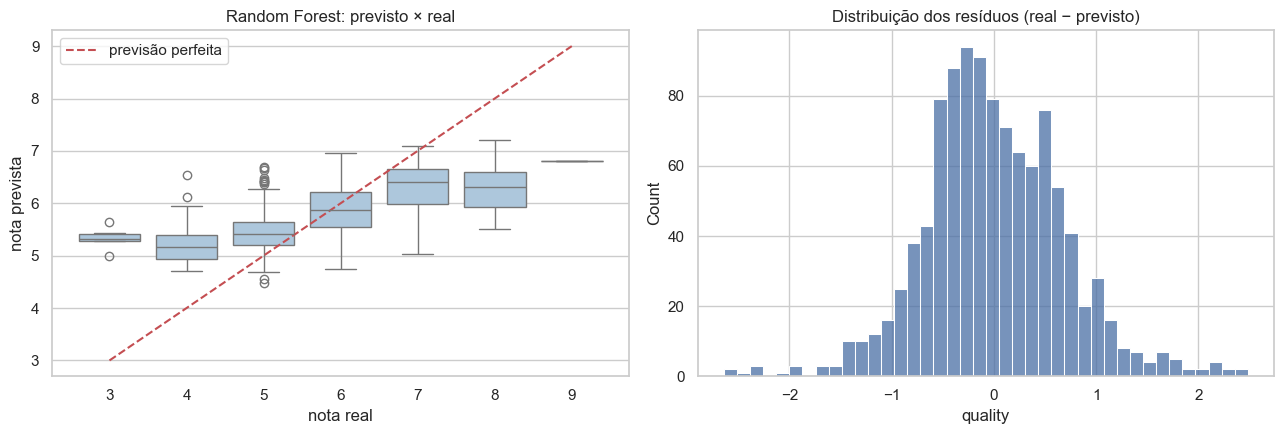

,size,mean
nota,,
3,6,-2.330
4,41,-1.238
5,354,-0.459
6,469,0.119
7,173,0.666
8,30,1.710
9,1,2.192


In [16]:
print(f"Modelo selecionado no treino: {melhor_nome_reg}")
melhor_reg = melhores_reg[melhor_nome_reg]
pred = melhor_reg.predict(X_test)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(x=y_test, y=pred, ax=ax[0], color="#a5c8e4")
notas = np.sort(y_test.unique())
ax[0].plot(range(len(notas)), notas, "r--", label="previsão perfeita")
ax[0].set_xlabel("nota real"); ax[0].set_ylabel("nota prevista")
ax[0].set_title(f"{melhor_nome_reg}: previsto × real"); ax[0].legend()
sns.histplot(y_test - pred, bins=40, ax=ax[1], color="#4a6fa5")
ax[1].set_title("Distribuição dos resíduos (real − previsto)")
plt.tight_layout()
plt.show()
residuos = pd.DataFrame({"nota": y_test, "previsto": pred, "erro": y_test - pred})
resumo_residuos = residuos.groupby("nota")["erro"].agg(["size", "mean"])
display(resumo_residuos.round(3))

Selecionado pela validação cruzada, o Random Forest obteve RMSE de 0,691, MAE de 0,533 e R² de 0,381 no teste. O RMSE foi 21,3% menor que o da referência pela média (0,879). O resíduo médio (real menos previsto) foi de −1,24 na nota 4 (41 casos) e +1,71 na nota 8 (30 casos). O modelo tende a superestimar notas baixas e subestimar notas altas.

### 4.4 Interpretação — quais variáveis mais impactam a nota?
**Coeficientes da Regressão Linear:** nas variáveis numéricas, cada coeficiente indica a variação
estimada na nota para um aumento de **1 desvio-padrão**, mantendo as demais variáveis constantes.
O coeficiente de `type_white` compara o vinho branco com o tinto, a categoria de referência.

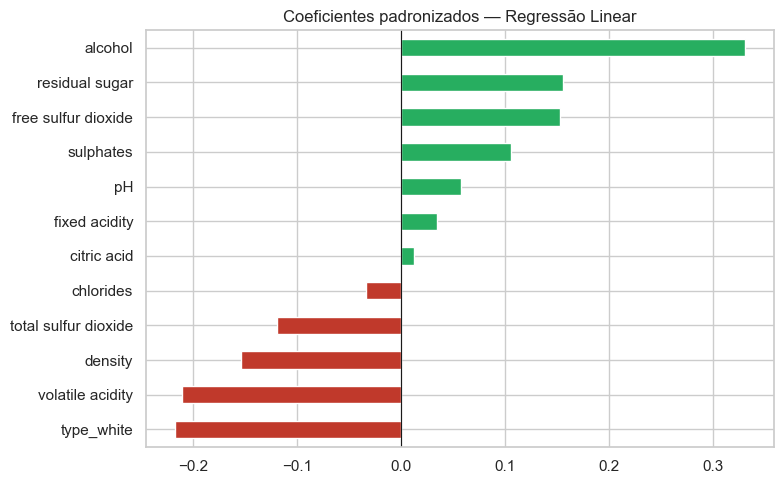

,Linear,Ridge
alcohol,0.331,0.332
chlorides,-0.034,-0.033
citric acid,0.013,0.013
density,-0.154,-0.147
fixed acidity,0.034,0.033
free sulfur dioxide,0.153,0.152
pH,0.058,0.057
residual sugar,0.156,0.151
sulphates,0.106,0.106
total sulfur dioxide,-0.120,-0.122


In [17]:
lin = melhores_reg["Regressão Linear"]
coef = pd.Series(lin.named_steps["modelo"].coef_,
                 index=lin.named_steps["prep"].get_feature_names_out()).sort_values()
ridge = melhores_reg["Ridge"]
coef_ridge = pd.Series(ridge.named_steps["modelo"].coef_,
                       index=ridge.named_steps["prep"].get_feature_names_out())

fig, ax = plt.subplots(figsize=(8, 5))
coef.plot.barh(ax=ax, color=["#c0392b" if c < 0 else "#27ae60" for c in coef])
ax.set_title("Coeficientes padronizados — Regressão Linear"); ax.axvline(0, color="k", lw=.8)
plt.tight_layout()
plt.show()
pd.DataFrame({"Linear": coef, "Ridge": coef_ridge}).round(3)

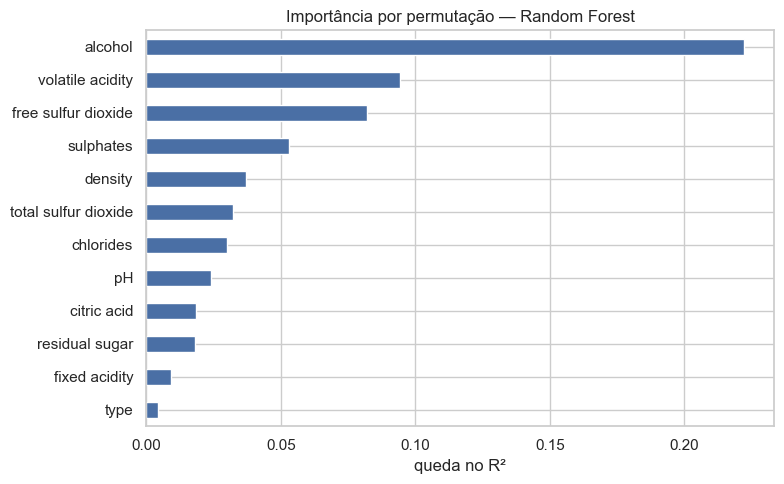

In [18]:
# Importância por permutação no teste: quanto o R² cai ao embaralhar cada variável.
# Mede a dependência do modelo já ajustado; preditores correlacionados podem compartilhar efeito.
with parallel_config(backend="threading"):
    imp = permutation_importance(melhor_reg, X_test, y_test, n_repeats=10, random_state=SEED,
                                 scoring="r2", n_jobs=N_JOBS)
imp_reg = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
ax = imp_reg.plot.barh(figsize=(8, 5), color="#4a6fa5",
                  title=f"Importância por permutação — {melhor_nome_reg}")
plt.xlabel("queda no R²")
plt.tight_layout()
plt.show()

### 4.5 Discussão da regressão
Na regressão linear, um desvio-padrão a mais de álcool está associado a +0,331 ponto de nota e um desvio-padrão a mais de acidez volátil, a −0,210 ponto, dadas as outras variáveis. O açúcar residual (+0,156) e a densidade (−0,154) têm coeficientes de sinais opostos e correlação de +0,53 entre si. No Random Forest, embaralhar álcool reduziu o R² em 0,222, seguido de acidez volátil (0,094) e SO₂ livre (0,082). São medidas de associação e de dependência do modelo.

## 5. Parte 2 — Classificação (faixas de qualidade)

### 5.1 Criação da variável alvo categórica — testando diferentes faixas
O enunciado pede para testar diferentes *ranges*. Testamos três discretizações:

| Esquema | Faixas | Ideia |
|---|---|---|
| **A** | baixa (0–4) · média (5–6) · alta (7–10) | faixas "naturais" da escala sensorial |
| **B** | baixa (0–5) · média (6) · alta (7–10) | divide a massa central, classes menos desiguais |
| **C** | ruim (0–5) · bom (6–10) | binário, o mais equilibrado |

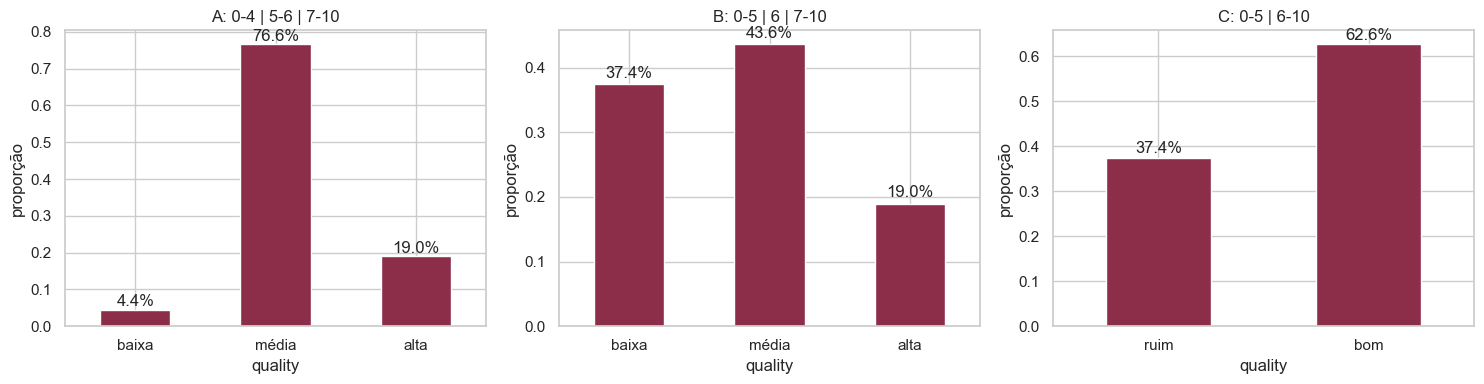

In [19]:
ESQUEMAS = {
    "A: 0-4 | 5-6 | 7-10": ([0, 4, 6, 10], ["baixa", "média", "alta"]),
    "B: 0-5 | 6 | 7-10":   ([0, 5, 6, 10], ["baixa", "média", "alta"]),
    "C: 0-5 | 6-10":       ([0, 5, 10], ["ruim", "bom"]),
}


def discretizar(notas, esquema):
    limites, rotulos = ESQUEMAS[esquema]
    return pd.cut(notas, bins=limites, labels=rotulos, include_lowest=True).astype(str)


distribuicao_faixas = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, esquema in zip(axes, ESQUEMAS):
    contagens = discretizar(y_train, esquema).value_counts().reindex(ESQUEMAS[esquema][1], fill_value=0)
    distribuicao_faixas[esquema] = contagens.to_dict()
    dist = contagens / len(y_train)
    dist.plot.bar(ax=ax, color="#8c2d4a", rot=0)
    ax.set_title(esquema); ax.set_ylabel("proporção")
    for i, v in enumerate(dist):
        ax.text(i, v + .01, f"{v:.1%}", ha="center")
plt.tight_layout()
plt.show()

No esquema A (0–4, 5–6, 7–10), as classes baixa, média e alta têm 4,4%, 76,6% e 19,0% do treino. No B (0–5, 6, 7–10), as proporções são 37,4%, 43,6% e 19,0%. No C (0–5, 6–10), as duas classes ficam em 37,4% e 62,6%. O esquema A é o foco para preservar três faixas e avaliar explicitamente a dificuldade com a classe baixa.

### 5.2 Escolha da métrica
Como as classes são **desbalanceadas**, a acurácia engana: um modelo que só prevê "média" já
acerta a maioria. Usamos o **F1-macro** como métrica principal — a média do F1 de cada classe, com
**peso igual** para todas — e a **acurácia balanceada** (média do recall por classe) como apoio.
Assim, errar todos os vinhos de qualidade baixa ou alta é punido de verdade.

### 5.3 Comparação inicial: 4 classificadores × 3 esquemas
Classificadores: **Regressão Logística**, **SVM (RBF)**, **Random Forest** e **HistGradientBoosting**,
todos com `class_weight="balanced"` (dá mais peso às classes raras) e um baseline que sempre
prevê a classe majoritária. Os rótulos de texto são convertidos em números com `LabelEncoder`.

In [20]:
def classificadores():
    return {
        "Baseline (majoritária)": DummyClassifier(strategy="most_frequent"),
        "Regressão Logística": LogisticRegression(max_iter=2000, class_weight="balanced"),
        "SVM (RBF)": SVC(class_weight="balanced", random_state=SEED),
        "Random Forest": RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=1),
        "HistGradientBoosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
    }


cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
linhas = []
for esquema in ESQUEMAS:
    # mesmo split do treino/teste da regressão (mesmos índices)
    y_tr = LabelEncoder().fit(ESQUEMAS[esquema][1]).transform(discretizar(y_train, esquema))
    for nome, modelo in classificadores().items():
        pipe = Pipeline([("prep", criar_preprocessador()), ("modelo", modelo)])
        with parallel_config(backend="threading"):
            res = cross_validate(
                pipe, X_train, y_tr, cv=cv_clf, n_jobs=N_JOBS, error_score="raise",
                scoring={"f1": "f1_macro", "bal": "balanced_accuracy", "acc": "accuracy"})
        linhas.append({"Esquema": esquema, "Modelo": nome, "F1-macro": res["test_f1"].mean(),
                       "Acur. balanceada": res["test_bal"].mean(), "Acurácia": res["test_acc"].mean()})
comparacao = pd.DataFrame(linhas)
comparacao.pivot(index="Modelo", columns="Esquema", values="F1-macro").round(4)

Esquema,A: 0-4 | 5-6 | 7-10,B: 0-5 | 6 | 7-10,C: 0-5 | 6-10
Modelo,,,
Baseline (majoritária),0.2892,0.2024,0.3849
HistGradientBoosting,0.5485,0.5877,0.7391
Random Forest,0.4679,0.6012,0.7477
Regressão Logística,0.4530,0.5539,0.7245
SVM (RBF),0.5040,0.5730,0.7367


In [21]:
comparacao.set_index(["Esquema", "Modelo"]).round(4)

F1-macro  Acur. balanceada  \
Esquema             Modelo                                               
A: 0-4 | 5-6 | 7-10 Baseline (majoritária)    0.2892            0.3333   
                    Regressão Logística       0.4530            0.6311   
                    SVM (RBF)                 0.5040            0.6524   
                    Random Forest             0.4679            0.4474   
                    HistGradientBoosting      0.5485            0.5374   
B: 0-5 | 6 | 7-10   Baseline (majoritária)    0.2024            0.3333   
                    Regressão Logística       0.5539            0.5949   
                    SVM (RBF)                 0.5730            0.6131   
                    Random Forest             0.6012            0.5872   
                    HistGradientBoosting      0.5877            0.5941   
C: 0-5 | 6-10       Baseline (majoritária)    0.3849            0.5000   
                    Regressão Logística       0.7245            0.7362   
                    SVM (RBF)                 0.7367            0.7486   
                    Random Forest             0.7477            0.7414   
                    HistGradientBoosting      0.7391            0.7437   

                                            Acurácia  
Esquema             Modelo                            
A: 0-4 | 5-6 | 7-10 Baseline (majoritária)    0.7660  
                    Regressão Logística       0.5374  
                    SVM (RBF)                 0.6158  
                    Random Forest             0.8016  
                    HistGradientBoosting      0.7702  
B: 0-5 | 6 | 7-10   Baseline (majoritária)    0.4361  
                    Regressão Logística       0.5579  
                    SVM (RBF)                 0.5769  
                    Random Forest             0.6210  
                    HistGradientBoosting      0.5942  
C: 0-5 | 6-10       Baseline (majoritária)    0.6258  
                    Regressão Logística       0.7327  
                    SVM (RBF)                 0.7446  
                    Random Forest             0.7716  
                    HistGradientBoosting      0.7518

Na comparação inicial por F1-macro, o HistGradientBoosting liderou o esquema A com 0,549. O Random Forest liderou B com 0,601 e C com 0,748. Cada esquema define um alvo diferente. O C tem duas classes e outro limiar, o que limita a comparação direta com as tarefas de três classes.

### 5.4 Esquema principal e balanceamento de classes
Aprofundamos no esquema **A: 0-4 | 5-6 | 7-10**. Comparamos três estratégias para lidar com o
desbalanceamento, usando o Random Forest:
1. **Nenhum ajuste**;
2. **`class_weight="balanced"`** — pesos inversamente proporcionais à frequência da classe;
3. **SMOTENC** — cria amostras sintéticas apenas nas dobras de treino. As 11 variáveis
   contínuas são preparadas primeiro e `type` chega ao amostrador como categoria.
   A codificação one-hot vem depois da amostragem, dentro do pipeline do imbalanced-learn.

In [22]:
ESQ = "A: 0-4 | 5-6 | 7-10"
codificador = LabelEncoder().fit(ESQUEMAS[ESQ][1])
y_train_c = codificador.transform(discretizar(y_train, ESQ))
# LabelEncoder numera as classes em ordem alfabética
print("Classes codificadas:", {str(c): int(i) for c, i in zip(codificador.classes_,
                                                            codificador.transform(codificador.classes_))})
print("Distribuição no treino:", pd.Series(codificador.inverse_transform(y_train_c)).value_counts().to_dict())

def criar_pipeline_clf(modelo, amostrador="passthrough"):
    preparo = ColumnTransformer([
        ("num", preparar_numericas(), FEATURES_NUM),
        ("tipo", "passthrough", ["type"]),
    ], verbose_feature_names_out=False).set_output(transform="pandas")
    codificacao = ColumnTransformer(
        [("tipo", codificar_tipo(), ["type"])], remainder="passthrough")
    return ImbPipeline([
        ("prep", preparo),
        ("amostrador", amostrador),
        ("codificacao", codificacao),
        ("modelo", modelo),
    ])


def criar_smotenc():
    return SMOTENC(categorical_features=["type"], random_state=SEED)


estrategias = {
    "Sem ajuste": criar_pipeline_clf(RandomForestClassifier(random_state=SEED, n_jobs=1)),
    "Pesos de classe": criar_pipeline_clf(
        RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=1)),
    "SMOTENC": criar_pipeline_clf(
        RandomForestClassifier(random_state=SEED, n_jobs=1), criar_smotenc()),
}
linhas = []
for nome, pipe in estrategias.items():
    with parallel_config(backend="threading"):
        res = cross_validate(pipe, X_train, y_train_c, cv=cv_clf, n_jobs=N_JOBS,
                             scoring={"f1": "f1_macro", "bal": "balanced_accuracy"},
                             error_score="raise")
    linhas.append({"Estratégia": nome, "F1-macro": res["test_f1"].mean(),
                   "Acur. balanceada": res["test_bal"].mean()})
resultado_balanceamento = pd.DataFrame(linhas).set_index("Estratégia")
resultado_balanceamento.round(4)

Classes codificadas: {'alta': 0, 'baixa': 1, 'média': 2}
Distribuição no treino: {'média': 3290, 'alta': 815, 'baixa': 190}


,F1-macro,Acur. balanceada
Estratégia,,
Sem ajuste,0.4958,0.4693
Pesos de classe,0.4869,0.4586
SMOTENC,0.5555,0.5633


Com o mesmo Random Forest, o F1-macro de validação foi 0,496 sem ajuste, 0,487 com pesos de classe e 0,556 com SMOTENC. A reamostragem sintética melhorou 0,060 em relação ao cenário sem ajuste. A configuração final da floresta também selecionou SMOTENC, com F1-macro de 0,565 em validação cruzada.

### 5.5 Ajuste de hiperparâmetros (GridSearchCV, F1-macro)

In [23]:
grades_clf = {
    "Regressão Logística": (
        LogisticRegression(max_iter=3000),
        {"amostrador": ["passthrough", criar_smotenc()],
         "modelo__C": [0.01, 0.1, 1, 10],
         "modelo__class_weight": [None, "balanced"]}),
    "SVM (RBF)": (
        SVC(class_weight="balanced", random_state=SEED),
        {"modelo__C": [1, 10, 30], "modelo__gamma": ["scale", 0.1, 0.3]}),
    "Random Forest": (
        RandomForestClassifier(random_state=SEED, n_jobs=1),
        {"amostrador": ["passthrough", criar_smotenc()],
         "modelo__class_weight": [None, "balanced_subsample"],
         "modelo__n_estimators": [200],
         "modelo__max_depth": [None, 15],
         "modelo__min_samples_leaf": [1, 3]}),
    "HistGradientBoosting": (
        HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
        {"modelo__learning_rate": [0.05, 0.1],
         "modelo__max_iter": [200, 400],
         "modelo__max_leaf_nodes": [15, 31]}),
}

melhores_clf = {}
buscas_clf = {}
for nome, (modelo, grade) in grades_clf.items():
    busca = GridSearchCV(criar_pipeline_clf(modelo), grade, cv=cv_clf, scoring="f1_macro",
                         n_jobs=N_JOBS, error_score="raise")
    with parallel_config(backend="threading"):
        busca.fit(X_train, y_train_c)
    melhores_clf[nome] = busca.best_estimator_
    parametros = {k: "SMOTENC" if isinstance(v, SMOTENC) else v
                  for k, v in busca.best_params_.items()}
    buscas_clf[nome] = {"F1-macro CV": busca.best_score_, "parâmetros": parametros}
    print(f"{nome:22s} F1-macro CV = {busca.best_score_:.4f}  |  {parametros}")

melhor_nome_clf = max(buscas_clf, key=lambda nome: buscas_clf[nome]["F1-macro CV"])
melhores_clf["Baseline (majoritária)"] = criar_pipeline_clf(
    DummyClassifier(strategy="most_frequent")).fit(X_train, y_train_c)

Regressão Logística    F1-macro CV = 0.4582  |  {'amostrador': 'SMOTENC', 'modelo__C': 1, 'modelo__class_weight': None}


SVM (RBF)              F1-macro CV = 0.5432  |  {'modelo__C': 1, 'modelo__gamma': 0.3}


Random Forest          F1-macro CV = 0.5648  |  {'amostrador': 'SMOTENC', 'modelo__class_weight': None, 'modelo__max_depth': None, 'modelo__min_samples_leaf': 3, 'modelo__n_estimators': 200}


HistGradientBoosting   F1-macro CV = 0.5583  |  {'modelo__learning_rate': 0.05, 'modelo__max_iter': 200, 'modelo__max_leaf_nodes': 15}


### 5.6 Avaliação final no conjunto de teste
Com as escolhas definidas no treino, usamos as notas de teste para avaliar a generalização.

In [24]:
y_test_c = codificador.transform(discretizar(y_test, ESQ))
linhas = []
for nome, pipe in melhores_clf.items():
    pred_c = pipe.predict(X_test)
    linhas.append({"Modelo": nome, "F1-macro": f1_score(y_test_c, pred_c, average="macro"),
                   "Acur. balanceada": balanced_accuracy_score(y_test_c, pred_c),
                   "Acurácia": (pred_c == y_test_c).mean()})
resultado_teste_clf = pd.DataFrame(linhas).set_index("Modelo")
resultado_teste_clf.round(4)

,F1-macro,Acur. balanceada,Acurácia
Modelo,,,
Regressão Logística,0.4570,0.6495,0.5410
SVM (RBF),0.5560,0.6523,0.6927
Random Forest,0.5667,0.6055,0.7412
HistGradientBoosting,0.5836,0.6415,0.7365
Baseline (majoritária),0.2892,0.3333,0.7663


Modelo selecionado no treino: Random Forest

              precision    recall  f1-score   support

       baixa      0.257     0.404     0.314        47
       média      0.867     0.790     0.826       823
        alta      0.508     0.623     0.559       204

    accuracy                          0.741      1074
   macro avg      0.544     0.606     0.567      1074
weighted avg      0.772     0.741     0.753      1074



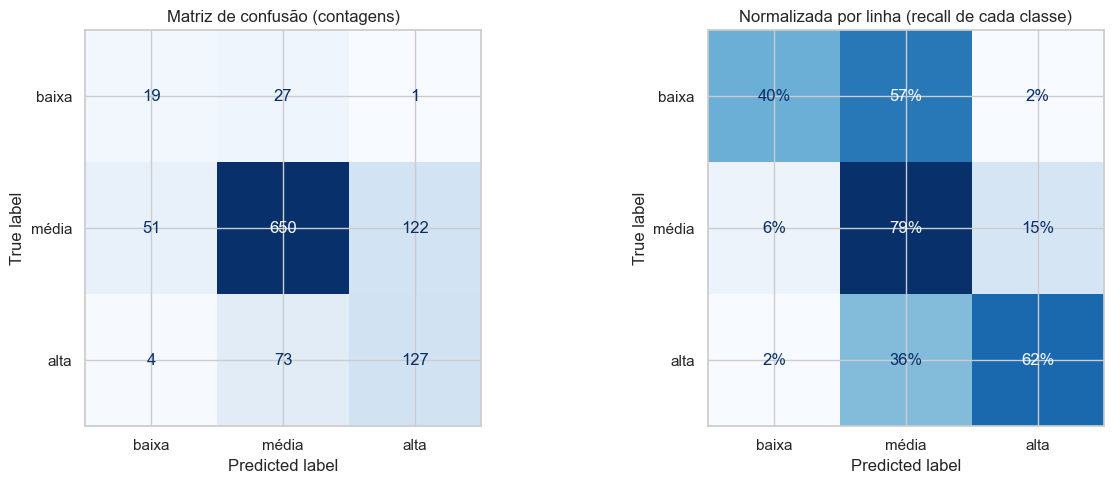

In [25]:
melhor_clf = melhores_clf[melhor_nome_clf]
pred_c = melhor_clf.predict(X_test)
print(f"Modelo selecionado no treino: {melhor_nome_clf}\n")
ordem = ESQUEMAS[ESQ][1]
idx = codificador.transform(ordem)
print(classification_report(y_test_c, pred_c, labels=idx, target_names=ordem,
                            digits=3, zero_division=0))
relatorio_classes = classification_report(y_test_c, pred_c, labels=idx, target_names=ordem,
                                          output_dict=True, zero_division=0)
matriz_confusao = confusion_matrix(y_test_c, pred_c, labels=idx)
assert matriz_confusao.sum() == len(y_test)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test_c, pred_c, labels=idx, display_labels=ordem,
                                        cmap="Blues", ax=ax[0], colorbar=False)
ax[0].set_title("Matriz de confusão (contagens)")
ConfusionMatrixDisplay.from_predictions(y_test_c, pred_c, labels=idx, display_labels=ordem,
                                        normalize="true", values_format=".0%", cmap="Blues",
                                        ax=ax[1], colorbar=False)
ax[1].set_title("Normalizada por linha (recall de cada classe)")
plt.tight_layout()
plt.show()

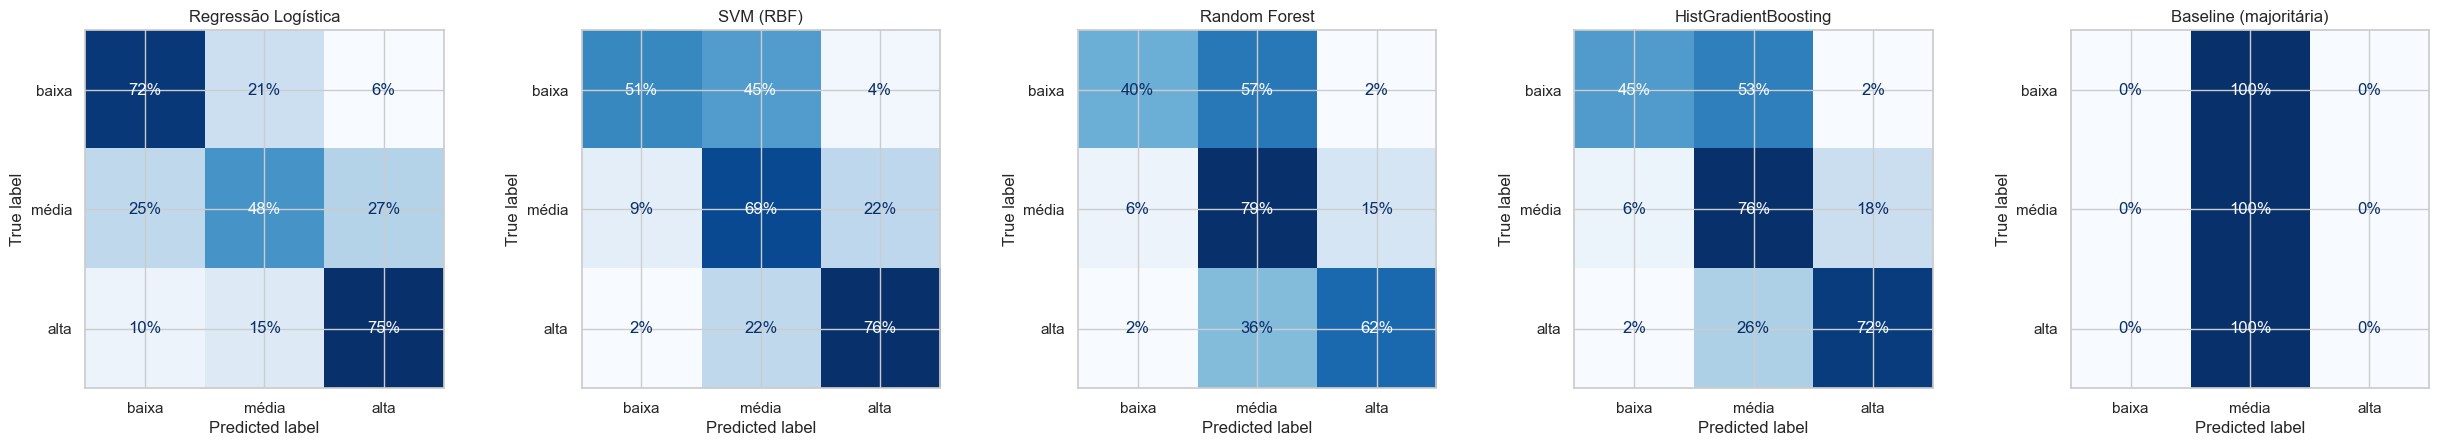

In [26]:
# Matrizes de confusão de todos os modelos ajustados, para comparar os padrões de erro
fig, axes = plt.subplots(1, len(melhores_clf), figsize=(5 * len(melhores_clf), 4.5))
for ax, (nome, pipe) in zip(axes, melhores_clf.items()):
    ConfusionMatrixDisplay.from_predictions(y_test_c, pipe.predict(X_test), labels=idx,
                                            display_labels=ordem, normalize="true",
                                            values_format=".0%", cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

In [27]:
# Quais notas originais são mais confundidas? (erros do melhor modelo por nota real)
erros = pd.DataFrame({"nota": y_test.values, "real": codificador.inverse_transform(y_test_c),
                      "previsto": codificador.inverse_transform(pred_c)})
erros["acertou"] = erros["real"] == erros["previsto"]
erros_por_nota = erros.groupby("nota")["acertou"].agg(n="count", acerto="mean")
erros_por_nota.round(3)

,n,acerto
nota,,
3,6,0.333
4,41,0.415
5,354,0.870
6,469,0.729
7,173,0.630
8,30,0.567
9,1,1.000


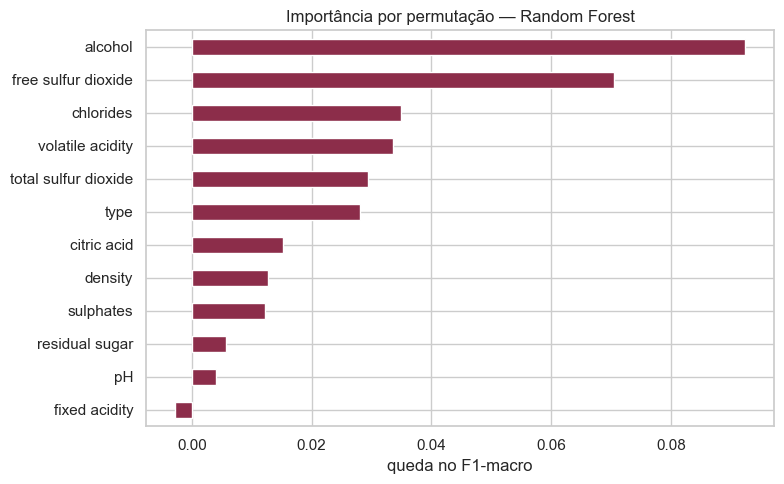

In [28]:
with parallel_config(backend="threading"):
    imp = permutation_importance(melhor_clf, X_test, y_test_c, n_repeats=10, random_state=SEED,
                                 scoring="f1_macro", n_jobs=N_JOBS)
imp_clf = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
ax = imp_clf.plot.barh(figsize=(8, 5), color="#8c2d4a",
                  title=f"Importância por permutação — {melhor_nome_clf}")
plt.xlabel("queda no F1-macro")
plt.tight_layout()
plt.show()

### 5.7 Discussão da classificação
O Random Forest foi selecionado em validação cruzada (F1-macro de 0,565). No teste, obteve F1-macro de 0,567 e acurácia balanceada de 0,606. O HistGradientBoosting marcou 0,584 no teste. A seleção permaneceu a definida no treino. A referência majoritária marcou 76,6% de acurácia, mas F1-macro de 0,289. A floresta recuperou 40,4% da classe baixa, 79,0% da média e 62,3% da alta. Dos 278 erros, 273 foram entre faixas vizinhas, incluindo 122 de média para alta. Embaralhar álcool e SO₂ livre reduziu o F1-macro em 0,092 e 0,070, respectivamente.

## 6. Conclusões
O Random Forest foi selecionado no treino para as duas tarefas. No teste, a regressão teve RMSE de 0,691 e R² de 0,381, e a classificação do esquema A teve F1-macro de 0,567. Álcool foi a variável de maior importância por permutação nas duas análises. A faixa baixa contém só 47 observações no teste e tem revocação de 40,4%. A pouca presença de extremos e o caráter sensorial da nota limitam a generalização.